<a href="https://colab.research.google.com/github/nizarbanu/RNN_2-RNN-Through-Time-and-Training/blob/main/RNN_Learner_Notebook_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## RNN Learner Notebook 2 — RNN Through Time and Training

### From Hidden States to Learning Through Time

This notebook builds on **RNN Learner Notebook 1**.

In Notebook 1, we learned:

> **Current Input + Previous Hidden State → Current Hidden State**

Now we ask:

> **How does an RNN produce outputs across a sequence, and how does it learn from errors that occur at different time steps?**

The focus of this notebook is **RNNs through time, sequence-to-output mappings, loss across time, Backpropagation Through Time (BPTT), and the limitations of vanilla RNNs**.


## 1. Learning Objectives

After completing this notebook, you should be able to:

1. Explain how an RNN processes a sequence through time.
2. Distinguish one-to-one, one-to-many, many-to-one and many-to-many mappings.
3. Explain how outputs can be generated at one or multiple time steps.
4. Explain how sequence loss is calculated.
5. Describe **Backpropagation Through Time (BPTT)**.
6. Trace how gradients flow backward through recurrent time steps.
7. Explain the vanishing-gradient and exploding-gradient problems.
8. Explain the limitations of a vanilla RNN.
9. Explain why LSTM and GRU were introduced.
10. Connect RNN training with the representation-learning perspective.

## 2. Connection with RNN Learner Notebook 1

In Notebook 1, we studied the hidden-state flow:

```text
x₁ → h₁
x₂ + h₁ → h₂
x₃ + h₂ → h₃
x₄ + h₃ → h₄
```

The hidden state carries information from earlier time steps.

Now we extend the picture:

```text
x₁ → h₁ → y₁
       ↓
x₂ → h₂ → y₂
       ↓
x₃ → h₃ → y₃
       ↓
x₄ → h₄ → y₄
```

The question is no longer only **how information moves forward**, but also:

> **How does the error move backward through the sequence during training?**

## 3. RNN Through Time

An RNN uses the same recurrent computation at every time step.

For each time step:

**Current Input + Previous Hidden State → Current Hidden State → Output**

Mathematically:

**hₜ = tanh(Wₓₕ xₜ + Wₕₕ hₜ₋₁ + bₕ)**

and

**yₜ = Wₕᵧ hₜ + bᵧ**

The important point is that the parameters are **shared across time steps**.

So an unrolled RNN is not a collection of independently trained networks. It is the **same recurrent computation applied repeatedly**.

## 4. A Small Forward-Pass Example

Consider a very simple scalar RNN:

**hₜ = tanh(w hₜ₋₁ + xₜ)**

Let:

- **w = 0.5**
- **h₀ = 0**
- **x₁ = 1**
- **x₂ = 0**
- **x₃ = 0**

### Step 1

**h₁ = tanh(0.5 × 0 + 1)**

**h₁ = tanh(1) ≈ 0.7616**

### Step 2

**h₂ = tanh(0.5 × 0.7616 + 0)**

**h₂ = tanh(0.3808) ≈ 0.3634**

### Step 3

**h₃ = tanh(0.5 × 0.3634 + 0)**

**h₃ = tanh(0.1817) ≈ 0.1797**

Notice what happened:

```text
x₁ = 1
   ↓
h₁ ≈ 0.7616
   ↓
h₂ ≈ 0.3634
   ↓
h₃ ≈ 0.1797
```

Even though **x₂ and x₃ are zero**, information originating at the first time step influences later hidden states.

In [15]:
import numpy as np

w = 0.5
h = 0.0
sequence = [1.0, 0.0, 0.0]

hidden_states = []

for x_t in sequence:
    h = np.tanh(w * h + x_t)
    hidden_states.append(h)

for t, h_t in enumerate(hidden_states, start=1):
    print(f"h_{t} = {h_t:.4f}")

h_1 = 0.7616
h_2 = 0.3634
h_3 = 0.1797


### Observe

The expected values are approximately:

```text
h₁ = 0.7616
h₂ = 0.3634
h₃ = 0.1797
```

This is a forward pass through time.

The next question is: **How can the network learn the value of `w`?**

## 5. RNN Input–Output Mappings

RNNs can be organized according to the number of inputs and outputs.

The four common patterns are:

1. One-to-one
2. One-to-many
3. Many-to-one
4. Many-to-many

The important idea is that these describe the **relationship between the input sequence structure and the output structure**.

## 6. One-to-One

A single input produces a single output.

```text
Input → Model → Output
```

Example:

```text
Image → Class Label
```

This is the conventional single-input, single-output setting.

It is **not a sequential RNN problem by itself**, but it provides a useful baseline for comparison.

## 7. One-to-Many

A single input produces a sequence of outputs.

```text
          → y₁
         ↗
Input → Model → y₂
         ↘
          → y₃
```

Examples include:

- Image captioning
- Music generation

For example:

```text
Image → "A" → "dog" → "runs"
```

The input is a single item, while the output develops across multiple time steps.

## 8. Many-to-One

A sequence produces a single output.

```text
x₁ → h₁
x₂ → h₂
x₃ → h₃ → Output
x₄ → h₄
```

Examples:

- Sentiment classification
- Sequence classification
- Rating prediction

For example:

```text
"The movie was excellent"
             ↓
        Positive
```

The sequence is processed over time, and the final representation can be used to produce one output.

## 9. Many-to-Many

A sequence produces a sequence of outputs.

```text
x₁ → h₁ → y₁
x₂ → h₂ → y₂
x₃ → h₃ → y₃
x₄ → h₄ → y₄
```

When the input and output sequences have corresponding time steps, examples include:

- Part-of-speech tagging
- Sequence labelling

For example:

```text
Words:       I     like     AI
Tags:       PRON   VERB    NOUN
```

The model produces an output for each relevant input position.

## 10. Many-to-Many with Different Sequence Lengths

Some sequence-to-sequence problems have:

**Input sequence length ≠ Output sequence length**

A common example is machine translation.

```text
Input sequence
**English sentence**
      ↓
   Encoder
      ↓
Internal representation
      ↓
   Decoder
      ↓
Output sequence
**Hindi sentence**
```

For example:

```text
"I am a student"
        ↓
"मैं एक विद्यार्थी हूँ"
```

This encoder-decoder idea will be revisited when sequence-to-sequence models are studied in greater depth.

## 11. Compare the Four Mappings

| Mapping | Input | Output | Example |
|---|---|---|---|
| One-to-one | Single | Single | Image classification |
| One-to-many | Single | Sequence | Image captioning |
| Many-to-one | Sequence | Single | Sentiment classification |
| Many-to-many | Sequence | Sequence | Part-of-speech tagging |

### Think

The mapping is determined by the **task**, not simply by the fact that an RNN is being used.

### Example 1 — One-to-Many: Image Caption Generation

One image is supplied, and the model generates a sequence of words step by step.

**Input:** one image  
**Output:** a caption such as “A dog is sitting on the grass.”

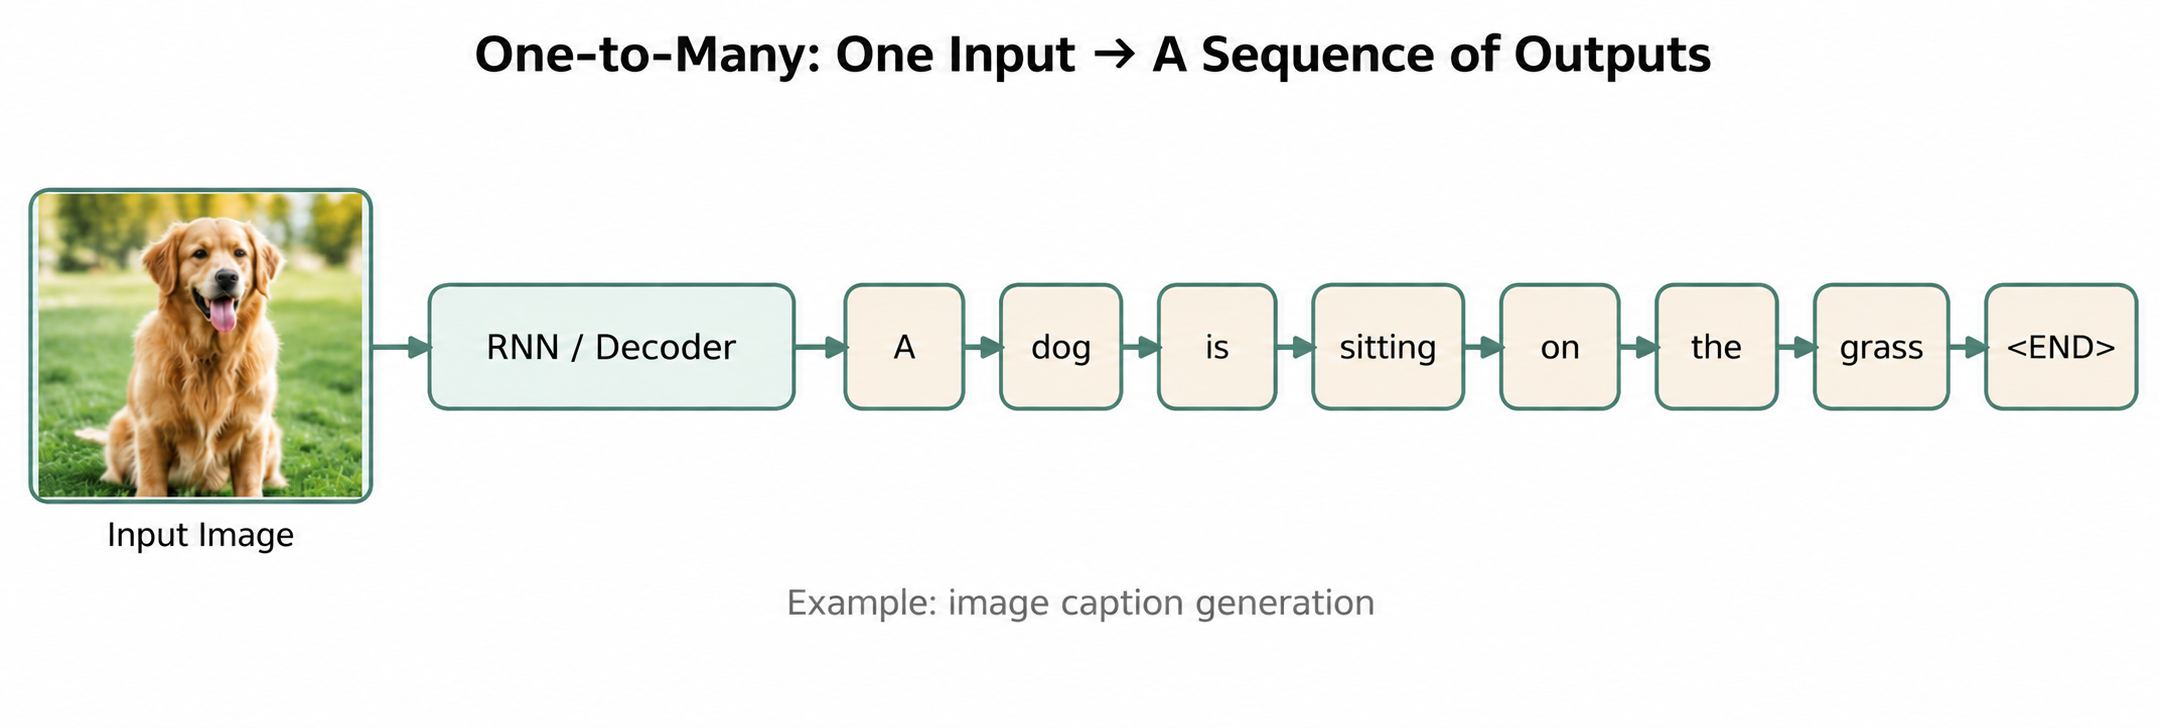

In [16]:
from IPython.display import display, Image
from pathlib import Path
import base64
from IPython.display import Markdown

image_path = "/content/One-to-Many Dog Caption Generation.png"

with open(image_path, "rb") as f:
    encoded = base64.b64encode(f.read()).decode("utf-8")

display(Markdown(
    f'<img src="data:image/png;base64,{encoded}" width="900">'
))

### Example 2 — Many-to-One: Sentiment Classification

The model processes a sequence of words and produces one overall label.

**Input:** “This movie is amazing.”  
**Output:** Positive sentiment

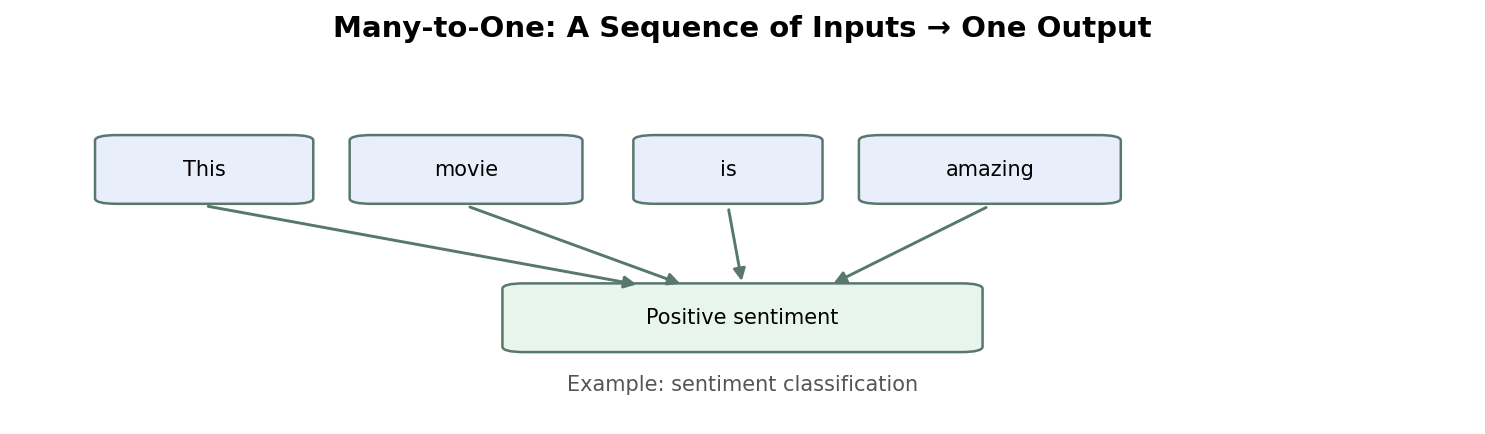

### Example 3 — Many-to-Many: Video Frame Labelling

Each input frame receives a corresponding output label. The input and output sequences are aligned by time step.

**Input:** video frames  
**Output:** Walking → Jogging → Running


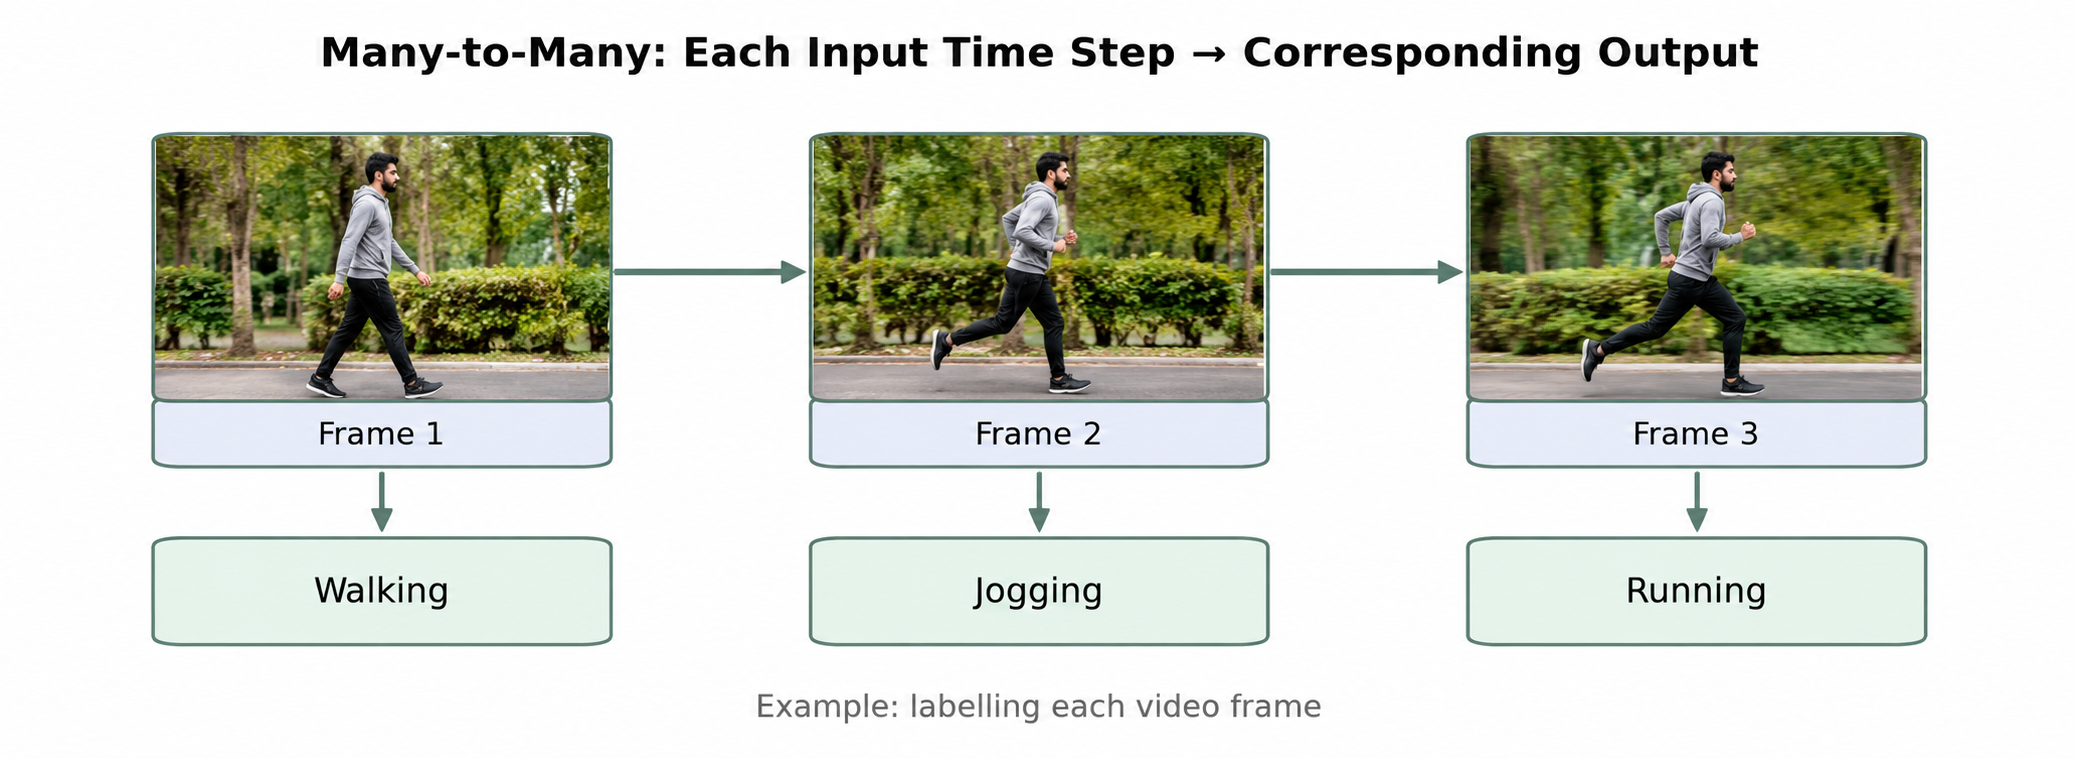

In [17]:
import base64
from IPython.display import display, HTML

image_path = "/content/Many-to-Many Video Action Sequence.png"

with open(image_path, "rb") as f:
    encoded_image = base64.b64encode(f.read()).decode("utf-8")

display(HTML(
    f'<img src="data:image/png;base64,{encoded_image}" '
    f'width="900" alt="Many-to-Many RNN sequence labelling">'
))

### Example 4 — Many-to-Many with Different Sequence Lengths: Machine Translation

The input and output sequences do not need to contain the same number of time steps. An encoder processes the input sequence, and a decoder generates the translated sequence.

**Input:** an English sentence  
**Output:** its translation, which may contain a different number of words.


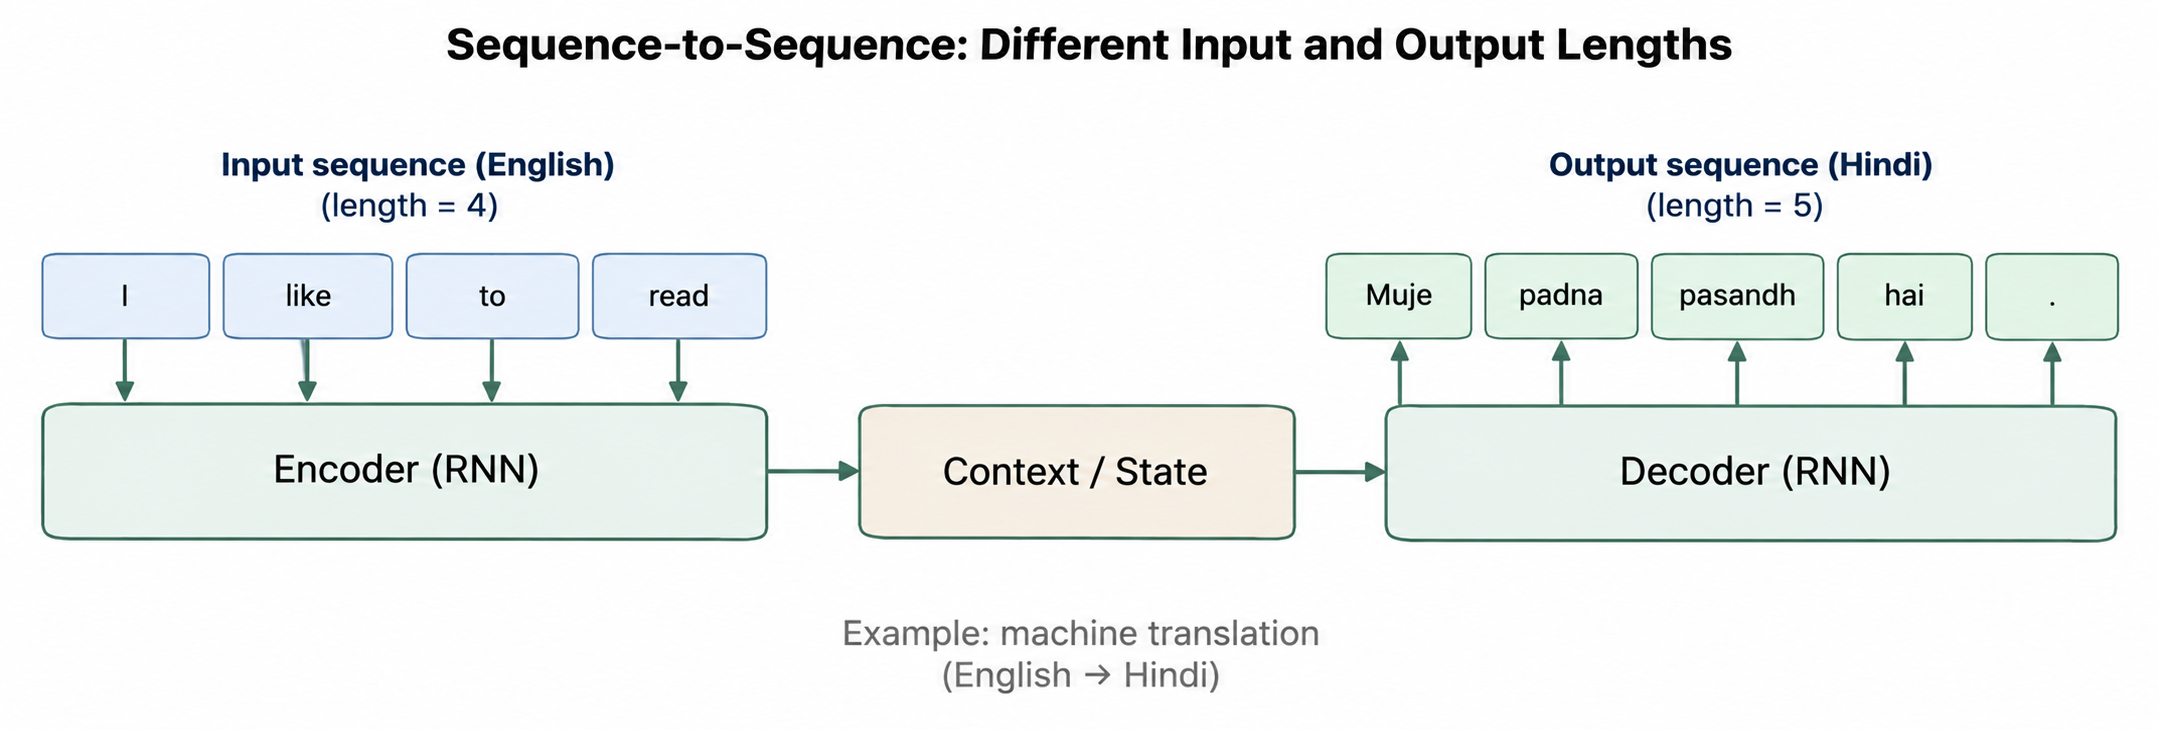

In [18]:
from IPython.display import display, HTML
import base64

image_path = "/content/Sequence-to-Sequence Translation Diagram.png"

with open(image_path, "rb") as f:
    encoded_image = base64.b64encode(f.read()).decode("utf-8")

display(HTML(f'''
<div style="text-align:center;">
    <img src="data:image/png;base64,{encoded_image}"
         alt="Sequence-to-Sequence RNN: English to Hindi"
         style="width:100%; max-width:1100px;">
</div>
'''))

## 12. Outputs at Different Time Steps

An RNN can produce an output at every time step:

```text
x₁ → h₁ → y₁
x₂ → h₂ → y₂
x₃ → h₃ → y₃
```

For a many-to-many task, each output may have its own target.

For a many-to-one task, we may use a selected hidden representation, commonly the final hidden state, to produce a single output.

The important question is:

> **Which outputs contribute to the learning objective?**

That determines how the loss is calculated.

## 13. Loss Across a Sequence

Suppose an RNN produces predictions at three time steps:

```text
y₁, y₂, y₃
```

and the corresponding targets are:

```text
t₁, t₂, t₃
```

If the loss at each time step is:

**L₁, L₂, L₃**

then a simple sequence loss can be written as:

**L = L₁ + L₂ + L₃**

In practice, losses may also be averaged across time steps or combined according to the task and framework.

The important idea is:

> **Errors from multiple time steps can contribute to the training objective.**

## 14. Why Training an RNN Is Different

For a feedforward network, information generally moves:

```text
Input → Layer → Layer → Output
```

For an RNN, information also flows across time:

```text
Time:
t₁ → t₂ → t₃ → t₄

Forward:
h₁ → h₂ → h₃ → h₄

Backward:
gradient ← gradient ← gradient ← gradient
```

Because the same recurrent parameters are used at different time steps, the training process must account for their influence across the whole sequence.

This leads to **Backpropagation Through Time (BPTT)**.

## 15. Backpropagation Through Time (BPTT)

**Backpropagation Through Time** is the application of backpropagation to the **unrolled RNN**.

Conceptually:

```text
Forward direction

x₁ → h₁ → h₂ → h₃ → h₄


Backward direction

x₁ ← h₁ ← h₂ ← h₃ ← h₄
             gradients
```

The recurrent network is viewed as an unrolled computational graph.

The error signal is propagated backward through the time steps.

##Note##
> **BPTT allows the network to learn how earlier inputs and hidden states contributed to later errors.**

## 16. A Simple BPTT Dependency

Consider:

**hₜ = tanh(w hₜ₋₁ + xₜ)**

The current hidden state depends on the previous hidden state.

Therefore, when we calculate how an earlier state affects a later state, the derivative contains a chain of terms.

For example:

**∂hₜ / ∂hₜ₋₁ = w(1 − hₜ²)**

For two steps:

**∂hₜ / ∂hₜ₋₂ = [w(1 − hₜ²)] [w(1 − hₜ₋₁²)]**

The multiplication continues as we move farther backward through time.

This repeated multiplication is central to understanding the **vanishing-gradient and exploding-gradient problems**.

## 17. Worked Numerical Example — Gradient Through Time

Consider:

**hₜ = tanh(w hₜ₋₁ + xₜ)**

with:

- **w = 0.5**
- **h₀ = 0**
- **x₁ = 1**
- **x₂ = 0**
- **x₃ = 0**

From the forward pass:

- **h₁ ≈ 0.7616**
- **h₂ ≈ 0.3634**
- **h₃ ≈ 0.1797**

Suppose the final loss is:

**L = 1/2 h₃²**

Then:

**∂L / ∂h₃ = h₃ ≈ 0.1797**

The recurrent derivative is:

**∂hₜ / ∂hₜ₋₁ = w(1 − hₜ²)**

For the last step:

**∂h₃ / ∂h₂ ≈ 0.5(1 − 0.1797²) ≈ 0.4839**

For the previous step:

**∂h₂ / ∂h₁ ≈ 0.5(1 − 0.3634²) ≈ 0.4340**

So the influence of an earlier state is obtained by multiplying these terms.

The important lesson is not memorising the decimal values. It is understanding the **repeated multiplication through time**.

In [19]:
import numpy as np

w = 0.5
h1 = 0.7615941559
h2 = 0.3633994844
h3 = 0.1797262071

dh3_dh2 = w * (1 - h3**2)
dh2_dh1 = w * (1 - h2**2)

print("∂h3/∂h2 =", round(dh3_dh2, 4))
print("∂h2/∂h1 =", round(dh2_dh1, 4))
print("Product  =", round(dh3_dh2 * dh2_dh1, 4))

∂h3/∂h2 = 0.4838
∂h2/∂h1 = 0.434
Product  = 0.21


### Interpretation

The product is smaller than either individual factor.

As the number of time steps increases, many such factors may be multiplied together.

This gives us the intuition for why gradients can become extremely small or extremely large.

## 18. Vanishing Gradient Problem

During BPTT, gradients can involve repeated multiplication by terms such as:

**w(1 − hₜ²)**

If the magnitude of these terms is consistently less than 1, repeated multiplication can make the gradient very small.

Conceptually:

```text
Gradient
   ↓
× 0.5
   ↓
× 0.5
   ↓
× 0.5
   ↓
× 0.5
   ↓
Very small gradient
```

When the gradient becomes very small, updates to parameters associated with earlier time steps become weak.

### Consequence

The vanilla RNN may struggle to learn **long-term dependencies**.

Information from distant time steps can become difficult to use effectively during learning.

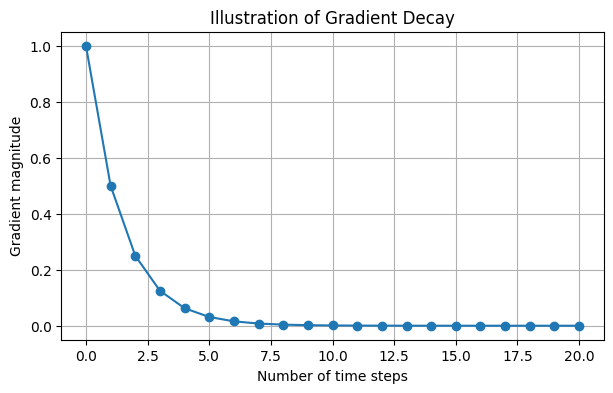

In [20]:
import numpy as np
import matplotlib.pyplot as plt

steps = np.arange(0, 21)
gradient = 0.5 ** steps

plt.figure(figsize=(7, 4))
plt.plot(steps, gradient, marker="o")
plt.xlabel("Number of time steps")
plt.ylabel("Gradient magnitude")
plt.title("Illustration of Gradient Decay")
plt.grid(True)
plt.show()

### Observe

The graph illustrates the general idea of gradient decay.

This is an **illustration**, not a complete RNN training simulation. In an actual RNN, the gradient depends on the recurrent weights, activation derivatives, sequence length, and other factors.

## 19. Exploding Gradient Problem

The opposite can also occur.

If repeated factors have magnitude greater than 1, the gradient can grow rapidly:

```text
Gradient
   ↓
× 1.5
   ↓
× 1.5
   ↓
× 1.5
   ↓
× 1.5
   ↓
Very large gradient
```

Very large gradients can lead to:

- unstable parameter updates
- numerical instability
- training that becomes difficult to control

A common practical technique for dealing with exploding gradients is **gradient clipping**.

Gradient clipping limits the magnitude of the gradient before the parameter update.

## 20. Vanishing vs Exploding Gradients

| Problem | What happens? | Main effect |
|---|---|---|
| Vanishing gradient | Gradient becomes very small | Difficult to learn long-term dependencies |
| Exploding gradient | Gradient becomes very large | Unstable training and large updates |

### Remember

Both problems arise from the repeated application of the chain rule through many time steps.

The problems are related to the mathematical structure of recurrent learning, not simply to the number of neurons in the network.

## 21. Why Vanilla RNNs Struggle with Long-Term Dependencies

Suppose a sequence contains:

```text
x₁ → x₂ → x₃ → ... → x₂₀
```

and information at **x₁** is important for interpreting **x₂₀**.

During learning, the influence of the early time step must travel through many recurrent computations.

```text
x₁
 ↓
h₁
 ↓
h₂
 ↓
h₃
 ↓
...
 ↓
h₂₀
```

During BPTT, the gradient must travel back through the same chain.

If the gradient becomes too small, the network has difficulty learning the long-range dependency.

This is one of the major limitations of the vanilla RNN.

## 22. What Do We Need From a Better Recurrent Architecture?

We would like a recurrent model that can:

- retain useful information for longer periods,
- reduce the difficulty of learning long-term dependencies,
- control what information is retained,
- control what new information is added, and
- control what information is exposed as output.

This motivates **gated recurrent architectures**.

Two important architectures are:

**LSTM — Long Short-Term Memory**

**GRU — Gated Recurrent Unit**

## 23. Why LSTM Was Introduced

LSTM introduces additional mechanisms called **gates** and a **cell state** to provide more controlled information flow.

At a high level, an LSTM can learn:

```text
What should be forgotten?
        ↓
What new information should be stored?
        ↓
What information should be exposed?
```

The important point for this notebook is:

> **LSTM was designed to improve the ability of recurrent networks to learn long-term dependencies.**

We will study the internal gates and equations separately rather than treating LSTM as simply "an RNN with more layers."

## 24. GRU

The **Gated Recurrent Unit (GRU)** is another gated recurrent architecture.

It uses gating mechanisms to control the flow of information through the recurrent computation.

Compared with LSTM, GRU has a simpler internal structure.

At this stage, remember:

```text
Vanilla RNN
     ↓
Difficulty with long-term dependencies
     ↓
Gated recurrent architectures
     ↓
LSTM / GRU
```

Detailed LSTM and GRU equations and implementation will be taken up in the subsequent learning stages.

## 25. Representation Learning Connection

Let us return to the representation-learning perspective.

In Notebook 1:

```text
x₁ → x₂ → x₃ → x₄
          ↓
       RNN
          ↓
h₁ → h₂ → h₃ → h₄
```

The hidden states form evolving representations of the sequence.

During training, BPTT adjusts the shared recurrent parameters so that these representations become useful for the task.

Therefore:

```text
Sequential Data
      ↓
Recurrent Processing
      ↓
Hidden-State Representation
      ↓
Task Loss
      ↓
BPTT
      ↓
Parameter Updates
      ↓
Improved Representation
```

This connects **representation learning** with **learning through time**.

## 26. Check Your Understanding

### Question 1

Why are the parameters shared across RNN time steps?

### Question 2

What is the difference between many-to-one and many-to-many RNN mappings?

### Question 3

Why can the loss of several time steps contribute to the total sequence loss?

### Question 4

What does BPTT mean?

### Question 5

Why can repeated multiplication during BPTT cause vanishing gradients?

### Question 6

What is the main difference between vanishing and exploding gradients?

### Question 7

Why was LSTM introduced?

### Question 8

Why should we not describe LSTM simply as "a deeper RNN"?

Think about each question before moving to the self-check.

In [21]:
answers = {
    "Q1": "The same learned transformation is applied repeatedly across time steps.",
    "Q2": "Many-to-one maps a sequence to one output; many-to-many produces outputs across a sequence.",
    "Q3": "Each relevant time step can produce an error that contributes to the training objective.",
    "Q4": "Backpropagation Through Time: backpropagation applied to the RNN unrolled across time.",
    "Q5": "Repeated multiplication by factors with magnitude below 1 can make the gradient very small.",
    "Q6": "Vanishing gradients become very small; exploding gradients become very large.",
    "Q7": "LSTM was designed to improve learning of long-term dependencies through controlled information flow.",
    "Q8": "LSTM changes the recurrent computation by introducing a memory cell and gates; it is not simply additional RNN depth."
}

for question, answer in answers.items():
    print(question, ":", answer)

Q1 : The same learned transformation is applied repeatedly across time steps.
Q2 : Many-to-one maps a sequence to one output; many-to-many produces outputs across a sequence.
Q3 : Each relevant time step can produce an error that contributes to the training objective.
Q4 : Backpropagation Through Time: backpropagation applied to the RNN unrolled across time.
Q5 : Repeated multiplication by factors with magnitude below 1 can make the gradient very small.
Q6 : Vanishing gradients become very small; exploding gradients become very large.
Q7 : LSTM was designed to improve learning of long-term dependencies through controlled information flow.
Q8 : LSTM changes the recurrent computation by introducing a memory cell and gates; it is not simply additional RNN depth.


## 27. Activity — Identify the RNN Mapping

Identify the most suitable input-output mapping for each task.

| Task | Mapping |
|---|---|
| Sentiment classification of a sentence | ? |
| Image caption generation | ? |
| Part-of-speech tagging | ? |
| Machine translation | ? |
| Single image classification | ? |

### Think Further

For each task, ask:

> **Is the input sequential? Is the output sequential? Are their lengths the same?**

## 28. Activity — Trace the Gradient

Consider:

```text
x₁ → h₁ → h₂ → h₃ → loss
```

Answer:

1. Which hidden state is closest to the loss?
2. Which hidden state is farthest from the loss?
3. Which state requires more recurrent steps for its influence to reach the loss?
4. Why might learning from the earliest time step be difficult?

### Extension

Change the recurrent factor in the gradient illustration from **0.5** to **0.9** and observe how the decay changes.

## 29. Reflection

Complete the following statements:

**Before this notebook, I thought BPTT was...**

**Now I understand that BPTT...**

**The vanishing-gradient problem means...**

**The exploding-gradient problem means...**

**LSTM and GRU were introduced because...**

**The most important connection with representation learning is...**

## 30. Summary — What You Should Remember

- An RNN processes a sequence **through time**.
- The same recurrent parameters are shared across time steps.
- RNNs can support one-to-one, one-to-many, many-to-one and many-to-many task structures.
- Sequence loss can combine losses from multiple relevant time steps.
- **BPTT** applies backpropagation to the RNN unrolled through time.
- Gradients can become very small, producing the **vanishing-gradient problem**.
- Gradients can also become very large, producing the **exploding-gradient problem**.
- Vanilla RNNs can therefore struggle with long-term dependencies.
- **LSTM and GRU** introduce gating mechanisms to improve information flow and learning of long-term dependencies.
- RNN hidden states provide learned representations of sequential information.

### Core Flow

```text
Sequence
   ↓
RNN Through Time
   ↓
Hidden States
   ↓
Outputs
   ↓
Loss
   ↓
BPTT
   ↓
Parameter Updates
   ↓
Improved Sequential Representation
```

## 31. What Comes Next?

We now understand:

**what an RNN is → how it works through time → how it learns → why vanilla RNNs have limitations.**

In **RNN Learner Notebook 3**, we will move to implementation and experimentation.

We will:

- build an RNN using TensorFlow/Keras,
- prepare sequential data,
- understand input shapes,
- train an RNN,
- observe predictions,
- experiment with sequence length and hidden units, and
- interpret the learned behaviour.

The next stage will connect the concepts developed here with an actual working RNN model.

## References

1. **Dive into Deep Learning — Recurrent Neural Networks**  
   https://d2l.ai/chapter_recurrent-neural-networks/rnn.html

2. **GeeksforGeeks — Introduction to Recurrent Neural Network**  
   https://www.geeksforgeeks.org/machine-learning/introduction-to-recurrent-neural-network/

